# Task 49: Manual Bayesian Hyperparameter Optimization

Implement an RBF Gaussian-process surrogate and expected-improvement acquisition directly with NumPy, then optimize scratch logistic-regression settings using cross-validation.

,evaluation,l2,learning_rate,iterations,mean_cv_f1,fold_f1_sd
0,1,0.0020,0.0550,1000,0.8309,0.0460
1,2,0.0316,0.0850,1500,0.8336,0.0441
2,3,0.0079,0.0700,1200,0.8363,0.0395
3,4,0.0044,0.0201,1800,0.8321,0.0467
4,5,0.0012,0.1102,1800,0.8417,0.0444
5,6,0.0020,0.0561,1600,0.8384,0.0430
6,7,0.0924,0.0272,1000,0.8347,0.0448
7,8,0.0649,0.0412,1700,0.8347,0.0448


Best settings: {'l2': np.float64(0.0012459992761522248), 'learning_rate': np.float64(0.11017595804710188), 'iterations': 1800}
Held-out test metrics: {'accuracy': 0.8360655737704918, 'precision': 0.7948717948717948, 'recall': 0.9393939393939394, 'f1': 0.8611111111111112}


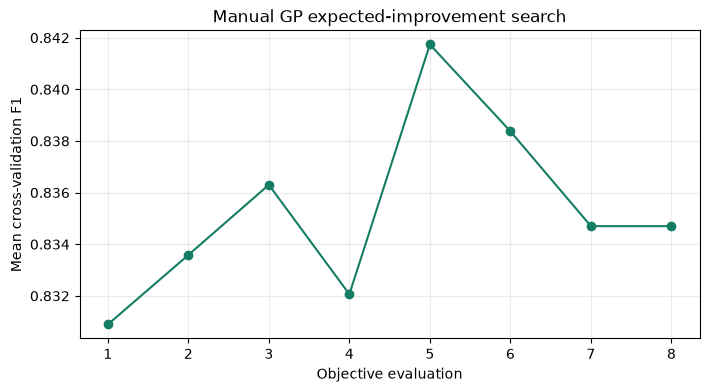

The RBF Gaussian-process posterior and expected improvement are computed with NumPy only; the test split was not searched.


In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

candidates=[Path('heart.csv'),Path('Task_49_Manual_Bayesian_Hyperparameter_Optimization/heart.csv'),Path('Heart_Disease_Tasks/Task_49_Manual_Bayesian_Hyperparameter_Optimization/heart.csv')]
data=pd.read_csv(next(path for path in candidates if path.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)

def split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)

trainval,test=split(y,.8,49);Xdev,Xtest=X[trainval],X[test];ydev,ytest=y[trainval],y[test]
def make_folds(labels,count=3,seed=49):
    rng=np.random.default_rng(seed);out=[[] for _ in range(count)]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids)
        for i,part in enumerate(np.array_split(ids,count)):out[i].extend(part.tolist())
    return [np.array(sorted(part)) for part in out]

folds=make_folds(ydev)
class ManualLogistic:
    def __init__(self,learning_rate,iterations,l2):self.rate,self.iterations,self.l2=learning_rate,iterations,l2
    def fit(self,x,y):
        self.weights=np.zeros(x.shape[1]);self.bias=0.
        for _ in range(self.iterations):
            probability=1/(1+np.exp(-np.clip(x@self.weights+self.bias,-35,35)));error=probability-y
            self.weights-=self.rate*(x.T@error/len(y)+self.l2*self.weights);self.bias-=self.rate*error.mean()
        return self
    def predict(self,x):return (1/(1+np.exp(-np.clip(x@self.weights+self.bias,-35,35)))>=.5).astype(int)

def f1(actual,predicted):
    tp=np.sum((actual==1)&(predicted==1));fp=np.sum((actual==0)&(predicted==1));fn=np.sum((actual==1)&(predicted==0))
    precision=tp/(tp+fp) if tp+fp else 0.;recall=tp/(tp+fn) if tp+fn else 0.
    return float(2*precision*recall/(precision+recall)) if precision+recall else 0.

def decode(point):
    return {'l2':10**(-3+2*point[0]),'learning_rate':.02+.10*point[1],'iterations':int(round((600+1200*point[2])/100)*100)}

def objective(point):
    settings=decode(point);scores=[]
    for valid in folds:
        held_out=set(valid.tolist());train=np.array([i for i in range(len(ydev)) if i not in held_out])
        xtr,xv=Xdev[train],Xdev[valid];ytr,yv=ydev[train],ydev[valid]
        mean,scale=xtr.mean(0),xtr.std(0);scale[scale==0]=1;xtr,xv=(xtr-mean)/scale,(xv-mean)/scale
        model=ManualLogistic(**settings).fit(xtr,ytr);scores.append(f1(yv,model.predict(xv)))
    return float(np.mean(scores)),float(np.std(scores,ddof=1))

def gp_predict(observed_x,observed_y,query_x,length_scale=.8):
    squared=np.sum((observed_x[:,None,:]-observed_x[None,:,:])**2,axis=2)
    covariance=np.exp(-.5*squared/length_scale**2)+np.eye(len(observed_y))*1e-5
    query_squared=np.sum((query_x[:,None,:]-observed_x[None,:,:])**2,axis=2)
    cross=np.exp(-.5*query_squared/length_scale**2)
    alpha=np.linalg.solve(covariance,observed_y)
    mean=cross@alpha
    solved=np.linalg.solve(covariance,cross.T)
    variance=np.maximum(1-np.sum(cross*solved.T,axis=1),1e-9)
    return mean,np.sqrt(variance)

def expected_improvement(mean,std,best,exploration=.01):
    z=(mean-best-exploration)/std
    cdf=.5*(1+np.vectorize(math.erf)(z/np.sqrt(2)))
    density=np.exp(-.5*z*z)/np.sqrt(2*np.pi)
    return (mean-best-exploration)*cdf+std*density

# Start with three space-filling points, then use GP posterior uncertainty and expected improvement.
rng=np.random.default_rng(490)
observed_x=[np.array([.15,.35,.35]),np.array([.75,.65,.75]),np.array([.45,.5,.5])]
observed_y=[];fold_sds=[];history=[]
for point in observed_x:
    score,spread=objective(point);observed_y.append(score);fold_sds.append(spread)
    history.append({'evaluation':len(history)+1,**decode(point),'mean_cv_f1':score,'fold_f1_sd':spread})
for _ in range(5):
    query=rng.random((80,3));mean,std=gp_predict(np.vstack(observed_x),np.array(observed_y),query)
    acquisition=expected_improvement(mean,std,max(observed_y));point=query[int(np.argmax(acquisition))]
    score,spread=objective(point);observed_x.append(point);observed_y.append(score);fold_sds.append(spread)
    history.append({'evaluation':len(history)+1,**decode(point),'mean_cv_f1':score,'fold_f1_sd':spread})

history_table=pd.DataFrame(history);best_index=int(np.argmax(observed_y));settings=decode(observed_x[best_index])
mean,scale=Xdev.mean(0),Xdev.std(0);scale[scale==0]=1
Xdev_scaled,Xtest_scaled=(Xdev-mean)/scale,(Xtest-mean)/scale
final_model=ManualLogistic(**settings).fit(Xdev_scaled,ydev);pred=final_model.predict(Xtest_scaled)
tp=np.sum((ytest==1)&(pred==1));tn=np.sum((ytest==0)&(pred==0));fp=np.sum((ytest==0)&(pred==1));fn=np.sum((ytest==1)&(pred==0))
precision=tp/(tp+fp) if tp+fp else 0.;recall=tp/(tp+fn) if tp+fn else 0.
display(history_table.round(4))
print('Best settings:',settings)
print('Held-out test metrics:',{'accuracy':float((tp+tn)/len(ytest)),'precision':float(precision),'recall':float(recall),'f1':f1(ytest,pred)})
fig,ax=plt.subplots(figsize=(8,4));ax.plot(history_table['evaluation'],history_table['mean_cv_f1'],marker='o',color='#147d64')
ax.set_xlabel('Objective evaluation');ax.set_ylabel('Mean cross-validation F1');ax.set_title('Manual GP expected-improvement search');ax.grid(alpha=.25);plt.show()
print('The RBF Gaussian-process posterior and expected improvement are computed with NumPy only; the test split was not searched.')